In [1]:
import pathlib

import navis.interfaces.neuprint as neu
import numpy as np
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import connectivity, plotting
from el_hd_plasticity.connectomics import synapse_distance as sd

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'      # written by el_hd_plasticity.connectomics.run_*synapse_distance
client = cn.npt_client()

# Distances without a search limit, so every synapse with an EL/ExR2 input on its neuron gets one; use
# '{type}_syn_distances.pkl' for the earlier search, capped at 10 microns Euclidean and 15 microns of cable.
DISTANCE_PICKLE = '{type}_syn_distances_uncapped.pkl'

## Example neurons

In [ ]:
ebcoords = cn.EBCoordinateSystem()
eb = ebcoords.fetch_roi('EB')

types = {'er4d': 'ER4d', 'er2': 'ER2.*', 'el': 'EL', 'epg': 'EPG', 'pen_a': 'PEN_a.*', 'pen_b': 'PEN_b.*'}
neurons = {name: neu.queries.fetch_neurons(neu.NeuronCriteria(type=t))[0] for name, t in types.items()}

example_er4d = neurons['er4d']['bodyId'].iloc[3]
example_el = connectivity.strongest_partner(example_er4d, neurons['el']['bodyId'])     # EL with most synapses onto it
example_epg = connectivity.strongest_partner(example_el, neurons['epg']['bodyId'])     # and the EPG onto that EL
exr2s, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='ExR2'))

skeletons = {'er4d': ebcoords.fetch_skeleton(example_er4d),
             'el': ebcoords.fetch_skeleton(example_el),
             'epg': ebcoords.fetch_skeleton(example_epg),
             'penb': ebcoords.fetch_skeleton(neurons['pen_b']['bodyId'].iloc[0]),
             'er2': ebcoords.fetch_skeleton(neurons['er2']['bodyId'].iloc[0])}

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/connectomics/connectomics.py:266: UserWarning: 
The coefficients of the spline returned have been computed as the
minimal norm least-squares solution of a (numerically) rank deficient
system (deficiency=92). If deficiency is large, the results may be
inaccurate. Deficiency may strongly depend on the value of eps.
  self._xsec_rad_spline = sp.interpolate.LSQBivariateSpline(eb_phase, xsec_phase, xsec_rad, knots, knots)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

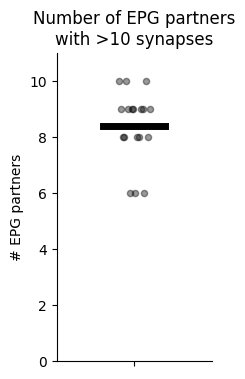

In [9]:
_, conn_df = connectivity.fetch_connections(neurons['epg']['bodyId'], neurons['el']['bodyId'], rois='EB', min_roi_weight=1)
n_partners = connectivity.count_partners(conn_df, neurons['el']['bodyId'], min_weight=10)

fig, ax = plt.subplots(figsize=(2, 4))
ax.scatter(np.linspace(-.1, .1, num=len(n_partners)), n_partners, color='k', s=20, alpha=.4)
ax.plot([-.2, .2], [n_partners.mean()] * 2, color='k', linewidth=5)
ax.set(ylim=[0, 11], xlim=[-.5, .5], xticks=[0], xticklabels=[''], ylabel='# EPG partners',
       title='Number of EPG partners\nwith >10 synapses')
ax.spines[['top', 'right']].set_visible(False)
fig.savefig(figfolder / 'EL_num_EPG_partners.pdf', bbox_inches='tight')

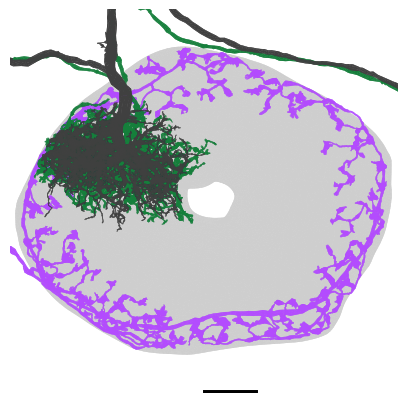

In [10]:
fig, ax = plotting.plot_neurons_2d(
    [eb, skeletons['er4d'], skeletons['el'], skeletons['epg']],
    colors=(plt.cm.cool(.7), plt.cm.Greens(.8), plt.cm.Greys(.8), plt.cm.Greys(.3)))
ax.set_xlim([-5100, 5000])
ax.set_ylim([-5000, 5000])
ax.plot([0, 1000 / 8 * 10], [-5000, -5000], linewidth=5, color='black')       # 10 micron line
fig.savefig(figfolder / 'er4d_epg_el_examples.png', dpi=500, transparent=True)

## Synapses of the example neurons

In [11]:
import neuprint as neu_orig

criteria = neu_orig.SynapseCriteria(rois='EB')
er4d_epg_synapses = cn.add_eb_coords(
    neu_orig.fetch_synapse_connections(example_er4d, example_epg, criteria), ebcoords, type='pre')
el_er4d_synapses = cn.add_eb_coords(
    neu_orig.fetch_synapse_connections(example_el, example_er4d, criteria), ebcoords, type='post')
exr2_er4d_synapses = cn.add_eb_coords(
    neu_orig.fetch_synapse_connections(example_er4d, exr2s, criteria), ebcoords, type='post')

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

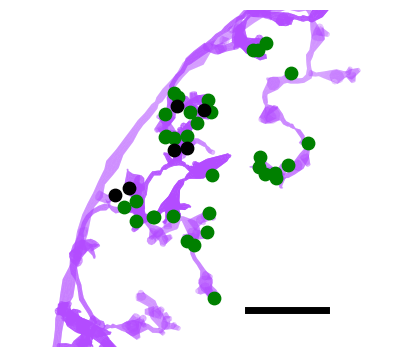

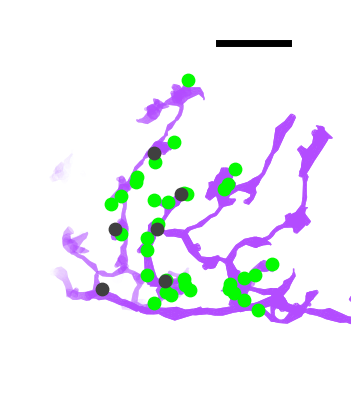

In [6]:
views = {  # plane: (shading axis, shading range, second synapse color, limits, scale bar y)
    'xy': dict(shade_by='z', smin=-2000, smax=700, ylim=[-300, 2400], bar_y=0, el_color='green', epg_color='black'),
    'xz': dict(shade_by='y', smin=5, smax=1800, ylim=[-2000, 1500], bar_y=1200, el_color=plt.cm.brg(.99),
               epg_color=plt.cm.Greys(.8)),
}
for plane, v in views.items():
    axes = tuple(plane)
    fig, ax = plotting.plot_neurons_2d([skeletons['er4d']], colors=plt.cm.cool(.7), view=axes, linewidth=1.,
                                       shade_by=v['shade_by'], smin=v['smin'], smax=v['smax'])
    for syn, color, z in ((er4d_epg_synapses, v['epg_color'], 101), (el_er4d_synapses, v['el_color'], 100)):
        ax.scatter(syn[f'{axes[0]}_eb'], syn[f'{axes[1]}_eb'], s=80, color=color, zorder=z)
    ax.set_xlim([-5100, -2000])
    ax.set_ylim(v['ylim'])
    ax.plot([-3200, -3200 + 1000 / 8 * 5], [v['bar_y']] * 2, linewidth=5, color='black')       # 5 micron line
    fig.savefig(figfolder / f'er4d_epg_el_examples_synapses_{plane}.png', dpi=500, transparent=True)

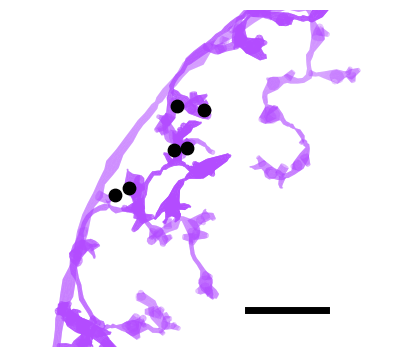

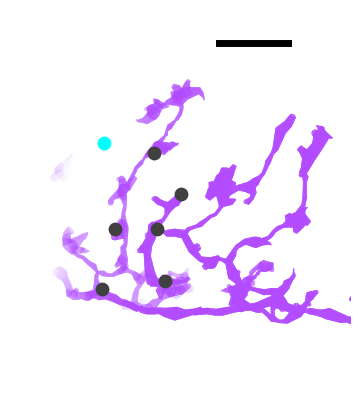

In [12]:
views = {  # plane: (shading axis, shading range, second synapse color, limits, scale bar y)
    'xy': dict(shade_by='z', smin=-2000, smax=700, ylim=[-300, 2400], bar_y=0, el_color='green', epg_color='black'),
    'xz': dict(shade_by='y', smin=5, smax=1800, ylim=[-2000, 1500], bar_y=1200, el_color=plt.cm.brg(.99),
               epg_color=plt.cm.Greys(.8)),
}
for plane, v in views.items():
    axes = tuple(plane)
    fig, ax = plotting.plot_neurons_2d([skeletons['er4d']], colors=plt.cm.cool(.7), view=axes, linewidth=1.,
                                       shade_by=v['shade_by'], smin=v['smin'], smax=v['smax'])
    for syn, color, z in ((er4d_epg_synapses, v['epg_color'], 101), (exr2_er4d_synapses, 'cyan', 100)):
        ax.scatter(syn[f'{axes[0]}_eb'], syn[f'{axes[1]}_eb'], s=80, color=color, zorder=z)
    ax.set_xlim([-5100, -2000])
    ax.set_ylim(v['ylim'])
    ax.plot([-3200, -3200 + 1000 / 8 * 5], [v['bar_y']] * 2, linewidth=5, color='black')       # 5 micron line
    # fig.savefig(figfolder / f'er4d_epg_el_examples_synapses_{plane}.png', dpi=500, transparent=True)

## Distance between EPG output synapses and EL / ExR2 input synapses on ER neurons

The search has no length limit (`run_synapse_distance.py --uncapped`), so every synapse gets a distance rather than only those with an
input within 10 microns Euclidean and 15 microns of cable. The histograms still span 0-16 microns, so a synapse whose nearest input is
further is off the right edge: 4% of the EL distances and 45% of the ExR2 ones.


In [ ]:
# distances computed by run_synapse_distance.py
distance_df = sd.load_distance_table(syndist_folder, sd.ER_TYPES, ('el_post', 'exr2_post'), filename=DISTANCE_PICKLE)
print(distance_df.groupby('source')['distances'].agg(
    synapses='size', median_microns='median', fraction_within_16=lambda d: (d <= 16).mean()).round(2))

er4d_er2 = distance_df.loc[distance_df['er'].isin(('ER4d', 'ER2_a', 'ER2_b', 'ER2_c', 'ER2_d'))]
fig, ax = plotting.plot_distance_histogram(er4d_er2, hue_order=('el', 'exr2'), palette=('green', 'blue'),
                                           bins=np.linspace(0, 16, 80))      # the scale of the other panels
ax.set_xlim([0, 16])
fig.savefig(figfolder / 'ER4d_dist_to_EPG_syn.pdf')

In [ ]:
for i, group in enumerate(sd.ER_GROUPS):
    fig, ax = plotting.plot_family_distance_histogram(distance_df, group, source='el')
    fig.savefig(figfolder / f'group{i}_dist_to_EPG_syn.pdf')

fig, axs = plotting.plot_cumulative_distances(distance_df, sd.ER_GROUPS)
fig.savefig(figfolder / 'all_dist_to_EPG_syn_cumulative.pdf', bbox_inches='tight')

## Number of partners of each ER neuron

In [ ]:
ers, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type=sd.ER_TYPES))
partners = {'EL': 'el', 'PEN_a': 'pen_a', 'PEN_b': 'pen_b', 'EPG': 'epg'}
partner_conn = {name: neu.queries.fetch_adjacencies(neurons[key]['bodyId'], ers['bodyId'], rois='EB')[1]
                for name, key in partners.items()}
partner_counts = sd.partner_count_table(partner_conn, ers, min_weight=3)

In [ ]:
for name, ymax in (('EL', 20), ('PEN_a', 20), ('PEN_b', 20), ('EPG', 40)):
    fig, ax = plotting.plot_partner_counts(partner_counts, name, f'Number of {name} partners\nwith >3 synapses',
                                           sd.ER_GROUPS, ymax=ymax)
    fig.savefig(figfolder / f'ER_type_num_{name.replace("_", "")}_partners.pdf', bbox_inches='tight')